# Classical Dataset
For the following experiments I generated a dataset of random binary vectors, $\vec x = <a,b>$ each labeled based on the following simple relationship:
$$
f(\vec x) = \begin{cases}1 \text{ if }2a + b \ge 6\\
0 \text{ otherwise}

\end{cases}
$$

The dataset is balanced on average and there's a 50% noise will flip the label on a vector.

# Gradient-Free
COBYLA test

In [1]:
from classifier_qnn_classical import *
import torch
from torch.nn import BCEWithLogitsLoss
from balanced_generator import generate_dataset
from scipy import optimize

x_train, y_train, x_test, y_test = generate_dataset(100)
x_train, y_train = torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)

convergence_classical = {"quantum_COBYLA":[], 'quantum_gd':[], 'quantum_ngd':[]}

def weight_format(weights):
    # Reshape the 1D array back to (num_layers, num_qubits, 3)
    tensor_weights = torch.tensor(weights, dtype=torch.float32)
    return tensor_weights.reshape(NUM_LAYERS, NUM_QUBITS, 3)

np.random.seed(0)
loss = BCEWithLogitsLoss()
def cost(weights):    
    x_batch, y_batch = stochastic_batch(x_train, y_train)
    fmtted_weights = weight_format(weights)
    output = quantum_circuit(x_batch, fmtted_weights).unsqueeze(1)
    
    return loss(output, y_batch).detach().cpu().item()
 
def log_loss(weights):
    convergence_classical['quantum_COBYLA'].append(cost(weights))

x_batch, y_batch = stochastic_batch(x_train, y_train)
output = qlayer(x_batch).unsqueeze(1)

convergence_classical['quantum_COBYLA'].append(loss(output, y_batch).detach().cpu().item())

_initial_weights = initial_weights.detach().cpu().numpy().flatten()
optimize.minimize(cost, _initial_weights, method='COBYLA', callback=log_loss, options={'maxiter':MAX_ITERATIONS, 'rhobeg':500000000, 'catol':1e-90, 'disp':True})
print(convergence_classical['quantum_COBYLA'])

<class 'torch.Tensor'>


/home/egaver1/quant_comp/balanced_generator.py:38: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_train = torch.tensor(x_train).to(dtype=torch.float32)
/home/egaver1/quant_comp/balanced_generator.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_train).to(dtype=torch.float32)
/home/egaver1/quant_comp/balanced_generator.py:41: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_test = torch.tensor(x_test).to(dtype=torch.float32)
/home/egaver1/quant_comp/balanced_generator.py:42: UserWarning: To copy construct from 


   Return from subroutine COBYLA because the MAXFUN limit has been reached.

   NFVALS =  400   F = 6.394998E-01    MAXCV = 0.000000E+00
   X = 4.857753E+08   5.061887E+08   5.377739E+08  -3.130833E+07  -5.064661E+07
      -4.518785E+07   5.590284E+08   5.218694E+08  -1.030081E+08  -3.988343E+07
      -1.919349E+06  -2.787741E+07  -2.548428E+07  -1.178913E+08  -1.192803E+06
      -2.868655E+06  -2.228143E+07  -1.328824E+08   6.061572E+01   1.628248E+00
       4.203099E+00  -2.456438E+07  -1.440219E+08  -1.282617E+07
[0.761317253112793, 0.7561125159263611, 0.7551956176757812, 0.7255011200904846, 0.7534425258636475, 0.766119122505188, 0.7624484300613403, 0.6804578304290771, 0.6658309698104858, 0.7465311288833618, 0.6926401853561401, 0.6672658324241638, 0.6836487054824829, 0.6938326358795166, 0.7608458995819092, 0.6671357750892639, 0.6702636480331421, 0.6804085969924927, 0.766362190246582, 0.6658309102058411, 0.6658309102058411, 0.6658309698104858, 0.6822758316993713, 0.677163302898407, 

# Gradient Methods
## Gradient Descent

In [ ]:
from torch.optim import SGD

optimizer = SGD(qlayer.parameters(), lr=0.7)
loss = BCEWithLogitsLoss()

np.random.seed(0)
for n in range(MAX_ITERATIONS):
    x_batch, y_batch = stochastic_batch(x_train, y_train)
        
    frwd = qlayer(x_batch).unsqueeze(1)
    
    lss = loss(frwd, y_batch)
    optimizer.zero_grad()
    lss.backward()
    optimizer.step()
    
    convergence_classical["quantum_gd"].append(lss.item())
    if n % 10 == 0:
        print(f"Epoch: {n} Training Loss:{lss}")
        

initial_weights: Parameter containing:
tensor([[[3.1181, 4.8269, 0.5559],
         [0.8296, 1.9316, 3.9840]],

        [[3.0793, 5.6325, 2.8628],
         [3.9729, 2.1922, 2.5241]],

        [[0.1403, 1.0610, 1.8466],
         [3.2580, 4.3836, 5.0266]],

        [[1.0118, 1.7735, 4.2827],
         [5.7503, 2.4951, 5.4925]]], requires_grad=True)
Epoch: 0 Training Loss:0.761317253112793
Epoch: 10 Training Loss:0.6455754637718201
Epoch: 20 Training Loss:0.6379441618919373
Epoch: 30 Training Loss:0.6346065402030945
Epoch: 40 Training Loss:0.6329866051673889
Epoch: 50 Training Loss:0.6321561932563782
Epoch: 60 Training Loss:0.63166743516922
Epoch: 70 Training Loss:0.6313384175300598
Epoch: 80 Training Loss:0.6310972571372986
Epoch: 90 Training Loss:0.6309121251106262
Epoch: 100 Training Loss:0.6307666301727295
Epoch: 110 Training Loss:0.6306509375572205
Epoch: 120 Training Loss:0.63055819272995
Epoch: 130 Training Loss:0.6304836273193359
Epoch: 140 Training Loss:0.6304232478141785
Epoch: 15

## Quantum Natural Gradient

In [3]:
from classifier_qnn_qng_classical import *

qlayer.weights.data = initial_weights

loss = BCEWithLogitsLoss()

metric_fn = qml.metric_tensor(quantum_circuit, approx="block-diag")
g_list = pnp.array([])
total_weights = weight_shape[0] * weight_shape[1] * weight_shape[2]

def calculate_batch_step(theta, x_batch, y_batch, lr=0.01, lam=1e-2, i=0):
    global g_list
    
    theta.requires_grad_()
    
    if i % 20 == 0:
        g_list = [metric_fn(theta, inputs=x).reshape(total_weights, total_weights) for x in x_batch]
        g_list = torch.stack(g_list)
   
    g_avg = torch.mean(g_list, axis=0)
    
    # this prevents some numerical stability issues especially when I'll be inverting it (Tikhonov regularization)
    g_reg = g_avg + lam * torch.eye(total_weights)
    
    
    batch_cost = loss(qlayer(x_batch).unsqueeze(1), y_batch)
    batch_cost.backward()
    grad_avg = theta.grad
    
    g_reg = g_reg.detach().numpy()
    grad_avg = grad_avg.detach().numpy().reshape((-1, 1))
    step = pnp.linalg.solve(g_reg, -lr * grad_avg)
    
    step = torch.tensor(step, dtype=torch.float32)
    theta_n = theta + step.reshape(theta.shape)
    
    return theta_n, batch_cost


np.random.seed(0)
for i in range(MAX_ITERATIONS):
    x_batch, y_batch = stochastic_batch(x_train, y_train)
    
    weights, cost = calculate_batch_step(qlayer.weights, x_batch, y_batch, i=i)
    qlayer.weights.data.copy_(weights)
    qlayer.weights.grad.zero_() 
    convergence_classical['quantum_ngd'].append(cost.item())
    if i % 10 == 0:
        print(f"Iteration {i}. The cost is: {cost}")
        

Initial weights: Parameter containing:
tensor([[[3.1181, 4.8269, 0.5559],
         [0.8296, 1.9316, 3.9840]],

        [[3.0793, 5.6325, 2.8628],
         [3.9729, 2.1922, 2.5241]],

        [[0.1403, 1.0610, 1.8466],
         [3.2580, 4.3836, 5.0266]],

        [[1.0118, 1.7735, 4.2827],
         [5.7503, 2.4951, 5.4925]]], requires_grad=True)
Iteration 0. The cost is: 0.761317253112793
Iteration 10. The cost is: 0.745538055896759
Iteration 20. The cost is: 0.7276756763458252
Iteration 30. The cost is: 0.7099708318710327
Iteration 40. The cost is: 0.6941002607345581
Iteration 50. The cost is: 0.6813844442367554
Iteration 60. The cost is: 0.6716791987419128
Iteration 70. The cost is: 0.6645806431770325
Iteration 80. The cost is: 0.6593725681304932
Iteration 90. The cost is: 0.6555388569831848
Iteration 100. The cost is: 0.6526454091072083
Iteration 110. The cost is: 0.6504153609275818
Iteration 120. The cost is: 0.6486455202102661
Iteration 130. The cost is: 0.6472062468528748
Iteratio

# Quantum Dataset
In the following experiemnts I used a synthetic dataset meant to immitate quantum data. The data used is meant to simulate a transverse field Ising model. Each ground state in the dataset is labeled as 0 or 1 and indicates the correct model to use based on the ground state of the system. The system is naturally modeled by qubits so I encode the ground states directly into the model's qubits.

# Gradient-Free
COBYLA Test. The noisy landscape may have impacted my ability to estimate an appropriate initial safety region size (rhobeg). I went large to hopefully offset the likely barren circuit cost space.

In [4]:
from classifier_qnn import *
import torch
from torch.nn import BCEWithLogitsLoss
from ising_model_data import generate_dataset
from scipy import optimize

x_train, y_train = generate_dataset(100)
x_train, y_train = torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)

y_train = torch.unsqueeze(y_train, 1)

convergence = {"quantum_COBYLA":[], 'quantum_gd':[], 'quantum_ngd':[]}

def weight_format(weights):
    # Reshape the 1D array back to (num_layers, num_qubits, 3)
    tensor_weights = torch.tensor(weights, dtype=torch.float32)
    return tensor_weights.reshape(NUM_LAYERS, NUM_QUBITS, 3)

np.random.seed(0)
loss = BCEWithLogitsLoss()
def cost(weights):    
    x_batch, y_batch = stochastic_batch(x_train, y_train)
    fmtted_weights = weight_format(weights)
    output = quantum_circuit(x_batch, fmtted_weights).unsqueeze(1)
    
    return loss(output, y_batch).detach().cpu().item()
 
def log_loss(weights):
    convergence['quantum_COBYLA'].append(cost(weights))

x_batch, y_batch = stochastic_batch(x_train, y_train)
output = qlayer(x_batch).unsqueeze(1)

convergence['quantum_COBYLA'].append(loss(output, y_batch).detach().cpu().item())

initial_weights = initial_weights.detach().cpu().numpy().flatten()
optimize.minimize(cost, initial_weights, method='COBYLA', callback=log_loss, options={'maxiter':MAX_ITERATIONS, 'rhobeg':500000000, 'catol':1e-90, 'disp':True})
    


   Return from subroutine COBYLA because the MAXFUN limit has been reached.

   NFVALS =  400   F = 5.719478E-01    MAXCV = 0.000000E+00
   X = 5.000000E+08   5.000000E+08   5.316943E-01   7.397438E-01   1.967834E+00
       5.000000E+08   5.000000E+08   5.640614E+00   2.855697E+00   5.000000E+08
       5.000000E+08   2.520702E+00   1.499184E-01   1.049251E+00   1.869990E+00
       3.269851E+00   4.414006E+00   4.955147E+00   1.002554E+00   5.000000E+08
       4.253977E+00   5.749081E+00   2.499881E+00   5.000000E+08


 message: Maximum number of function evaluations has been exceeded.
 success: False
  status: 2
     fun: 0.5719477534294128
       x: [ 5.000e+08  5.000e+08 ...  2.500e+00  5.000e+08]
    nfev: 400
   maxcv: 0.0

# Gradient Methods
I test batch stochastic gradient descent here and quantum natural gradient.

## Gradient Descent

In [5]:
from classifier_qnn import *
import torch
from torch.optim import SGD
from torch.nn import BCEWithLogitsLoss
from ising_model_data import generate_dataset

x_train, y_train = generate_dataset(100)
x_train, y_train = torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)

y_train = torch.unsqueeze(y_train, 1)

optimizer = SGD(qlayer.parameters(), lr=0.7)
loss = BCEWithLogitsLoss()

np.random.seed(0)
for n in range(MAX_ITERATIONS):
    x_batch, y_batch = stochastic_batch(x_train, y_train)
        
    frwd = qlayer(x_batch).unsqueeze(1)
    
    lss = loss(frwd, y_batch)
    optimizer.zero_grad()
    lss.backward()
    optimizer.step()
    
    convergence["quantum_gd"].append(lss.item())
    if n % 10 == 0:
        print(f"Epoch: {n} Training Loss:{lss}")
        

Epoch: 0 Training Loss:0.7598348259925842
Epoch: 10 Training Loss:0.6359003782272339
Epoch: 20 Training Loss:0.6114352345466614
Epoch: 30 Training Loss:0.5911369323730469
Epoch: 40 Training Loss:0.6012131571769714
Epoch: 50 Training Loss:0.5964949727058411
Epoch: 60 Training Loss:0.5925202965736389
Epoch: 70 Training Loss:0.5950020551681519
Epoch: 80 Training Loss:0.6056565642356873
Epoch: 90 Training Loss:0.5824452042579651
Epoch: 100 Training Loss:0.5922542810440063
Epoch: 110 Training Loss:0.5970919728279114
Epoch: 120 Training Loss:0.5923567414283752
Epoch: 130 Training Loss:0.5957047343254089
Epoch: 140 Training Loss:0.5760993361473083
Epoch: 150 Training Loss:0.5886038541793823
Epoch: 160 Training Loss:0.5955264568328857
Epoch: 170 Training Loss:0.5936338305473328
Epoch: 180 Training Loss:0.5814286470413208
Epoch: 190 Training Loss:0.5859483480453491
Epoch: 200 Training Loss:0.5842400193214417
Epoch: 210 Training Loss:0.5833176970481873
Epoch: 220 Training Loss:0.575624406337738


## Quantum Natural Gradient

In [6]:
from classifier_qnn_qng import *
import torch
from torch.optim import SGD
from torch.nn import BCEWithLogitsLoss
from ising_model_data import generate_dataset

x_train, y_train = generate_dataset(100)
x_train, y_train = torch.tensor(x_train, dtype=torch.float32, requires_grad=False), torch.tensor(y_train, dtype=torch.float32, requires_grad=False)

y_train = torch.unsqueeze(y_train, 1)
x_train.requires_grad_(False)

loss = BCEWithLogitsLoss()



metric_fn = qml.metric_tensor(quantum_circuit, approx="block-diag")
g_list = pnp.array([])
total_weights = weight_shape[0] * weight_shape[1] * weight_shape[2]

def calculate_batch_step(theta, x_batch, y_batch, lr=0.01, lam=1e-2, i=0):
    global g_list
    
    theta.requires_grad_()
    
    if i % 20 == 0:
        g_list = [metric_fn(theta, inputs=x).reshape(total_weights, total_weights) for x in x_batch]
        g_list = torch.stack(g_list)
   
    g_avg = torch.mean(g_list, axis=0)
    
    # this prevents some numerical stability issues especially when I'll be inverting it (Tikhonov regularization)
    g_reg = g_avg + lam * torch.eye(total_weights)
    
    
    batch_cost = loss(qlayer(x_batch).unsqueeze(1), y_batch)
    batch_cost.backward()
    grad_avg = theta.grad
    
    g_reg = g_reg.detach().numpy()
    grad_avg = grad_avg.detach().numpy().reshape((-1, 1))
    step = pnp.linalg.solve(g_reg, -lr * grad_avg)
    
    step = torch.tensor(step, dtype=torch.float32)
    theta_n = theta + step.reshape(theta.shape)
    
    return theta_n, batch_cost


np.random.seed(0)
for i in range(MAX_ITERATIONS):
    x_batch, y_batch = stochastic_batch(x_train, y_train)
    
    weights, cost = calculate_batch_step(qlayer.weights, x_batch, y_batch, i=i)
    qlayer.weights.data.copy_(weights)
    qlayer.weights.grad.zero_()
    #weights, cost = calculate_step(weights, inp, inp_label) 
    convergence['quantum_ngd'].append(cost.item())
    if i % 10 == 0:
        print(f"Iteration {i}. The cost is: {cost}")
        

Iteration 0. The cost is: 0.7598348259925842
Iteration 10. The cost is: 0.7537522912025452
Iteration 20. The cost is: 0.7357610464096069
Iteration 30. The cost is: 0.7252262234687805
Iteration 40. The cost is: 0.7136772274971008
Iteration 50. The cost is: 0.7016466856002808
Iteration 60. The cost is: 0.696245014667511
Iteration 70. The cost is: 0.6841996908187866
Iteration 80. The cost is: 0.6808484792709351
Iteration 90. The cost is: 0.657764196395874
Iteration 100. The cost is: 0.6591156721115112
Iteration 110. The cost is: 0.6573041081428528
Iteration 120. The cost is: 0.6436853408813477
Iteration 130. The cost is: 0.6374356150627136
Iteration 140. The cost is: 0.6191723346710205
Iteration 150. The cost is: 0.6228498220443726
Iteration 160. The cost is: 0.62465900182724
Iteration 170. The cost is: 0.6179724335670471
Iteration 180. The cost is: 0.6047244668006897
Iteration 190. The cost is: 0.6064886450767517
Iteration 200. The cost is: 0.6008233428001404
Iteration 210. The cost is: 

# Graph

Empirical Decay Rates (Log-Scale Slope):
 - quantum_COBYLA : Log-Slope = -0.00029
 - quantum_gd     : Log-Slope = -0.00021
 - quantum_ngd    : Log-Slope = -0.00065
Empirical Decay Rates (Log-Scale Slope):
 - quantum_COBYLA : Log-Slope = -0.00008
 - quantum_gd     : Log-Slope = -0.00012
 - quantum_ngd    : Log-Slope = -0.00032


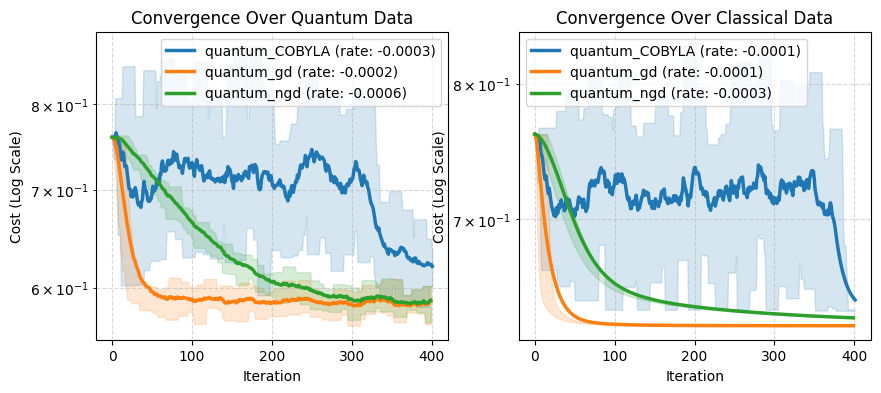

In [10]:
from matplotlib import pyplot as plt
import numpy as np

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4))

def compute_envelope(data, window=15, alpha=0.08):
    data_arr = np.array(data)
    ema = []
    current = data_arr[0]
    
    # just an exponential average of costs to decrease ugliness of jagged points
    for val in data_arr:
        current = alpha * val + (1 - alpha) * current
        ema.append(current)
    ema = np.array(ema)
    
    # maximum and minimum over window range
    rolling_min = np.array([np.min(data_arr[max(0, i - window):i + 1]) for i in range(len(data_arr))])
    rolling_max = np.array([np.max(data_arr[max(0, i - window):i + 1]) for i in range(len(data_arr))])
    
    return ema, rolling_min, rolling_max


def plot_convergence(convergence, axis, title):
    print("Empirical Decay Rates (Log-Scale Slope):")

    for method in convergence:
        if method == 'classical_gd':
            continue
            
        costs = np.array(convergence[method])
        iterations = np.arange(len(costs))
        
        ema_costs, min_bounds, max_bounds = compute_envelope(costs)
        
        # --- Compute Log-Linear Slope (Decay Rate Constant) ---
        # Shift slightly above 0 if costs reach exact zero to avoid log(0)
        log_costs = np.log(np.maximum(ema_costs, 1e-8))
        
        slope, intercept = np.polyfit(iterations, log_costs, 1)
        
        print(f" - {method:15s}: Log-Slope = {slope:.5f}")

        line, = axis.plot(iterations, ema_costs, linewidth=2.5, label=f"{method} (rate: {slope:.4f})")
        axis.fill_between(iterations, min_bounds, max_bounds, color=line.get_color(), alpha=0.18)

    axis.set_yscale('log')
    axis.set_xlabel("Iteration")
    axis.set_ylabel("Cost (Log Scale)")
    axis.set_title("Convergence Over " + title)
    axis.grid(True, which="both", linestyle="--", alpha=0.5)
    axis.legend()

plot_convergence(convergence, ax1, title="Quantum Data")
plot_convergence(convergence_classical, ax2, title="Classical Data")
#plt.savefig('enveloped_convergence_quantum_data.png')
plt.show()